In [1]:
from olist_utils import run_query, set_style, COLORS
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

set_style()

**复购口径的选择（D-022）**

我认为应该按购买日期, 因为同一天购买的很可能是因为当时同时有需要/受同一因素驱动购买可能性较大(即两单关联性相对较大), 并不能真实反映是由信任/服务等平台方面的因素而复购; 相比之下按日期定义复购更有可能是由于平台方面的因素影响该用户进行复购行为.

In [2]:
sql_rebuy = """
WITH rebuyers_on_orders AS(
  SELECT DISTINCT customer_unique_id, customer_unique_id AS count_o
  FROM dwd_orders
  WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0
  GROUP BY customer_unique_id
  HAVING COUNT(order_id) > 1
),
rebuyers_on_days AS (
  SELECT DISTINCT customer_unique_id, customer_unique_id AS count_d
  FROM dwd_orders
  WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0
  GROUP BY customer_unique_id
  HAVING DATEDIFF(MAX(DATE(purchase_ts)), MIN(DATE(purchase_ts))) >= 1
)
SELECT COUNT(DISTINCT customer_unique_id) AS buyers, COUNT(DISTINCT count_o) AS rep_buyers_o, COUNT(DISTINCT count_o) / COUNT(DISTINCT customer_unique_id) AS rate_rebuy_o, COUNT(DISTINCT count_d) AS rep_buyers_d, COUNT(DISTINCT count_d) / COUNT(DISTINCT customer_unique_id) AS rate_rebuy_d
FROM dwd_orders LEFT JOIN rebuyers_on_orders USING(customer_unique_id) LEFT JOIN rebuyers_on_days USING(customer_unique_id)
WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0
"""
df_rep = run_query(sql_rebuy)
df_rep

,buyers,rep_buyers_o,rate_rebuy_o,rep_buyers_d,rate_rebuy_d
0,93096,2789,0.03,2005,0.0215


In [3]:
# 求复购订单贡献了多少交易额
# 定义： 一笔订单如果下单日期晚于这个买家的首次购买日期，就是复购订单。
sql = """
WITH order_price AS (
  SELECT order_id, customer_unique_id, purchase_ts, SUM(price) AS gmv_per_order
  FROM dwd_orders JOIN dwd_order_items USING(order_id)
  WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0
  GROUP BY order_id, purchase_ts
),
first_order AS (
  SELECT order_id, purchase_ts, MIN(DATE(purchase_ts)) OVER (PARTITION BY customer_unique_id) AS first_day, gmv_per_order
  FROM order_price
)
SELECT COUNT(*) AS orders,
       SUM(gmv_per_order) AS total_gmv, 
       SUM(CASE WHEN DATE(purchase_ts) > first_day THEN gmv_per_order END) AS total_re_gmv, 
       SUM(CASE WHEN DATE(purchase_ts) > first_day THEN 1 END) AS re_orders, 
       SUM(CASE WHEN DATE(purchase_ts) > first_day THEN 1 END) / COUNT(*) AS rate_re_orders,
       SUM(CASE WHEN DATE(purchase_ts) > first_day THEN gmv_per_order END) / SUM(gmv_per_order) AS rate_re_gmv
FROM first_order
"""
df_rep_gmv = run_query(sql)
df_rep_gmv


,orders,total_gmv,total_re_gmv,re_orders,rate_re_orders,rate_re_gmv
0,96203,13179777.95,283162.58,2249.0,0.0234,0.021485


In [4]:
#探索数据截止会不会低估复购率
#按"首次购买年份"把买家分成2017年和2018年两组，查看一组的复购率更高
sql_cohort = """
WITH valid_order AS (
    SELECT order_id, customer_unique_id, purchase_ts
    FROM dwd_orders
    WHERE order_status = 'delivered' AND in_analysis_window = 1 AND is_status_conflict = 0
),
buyer_summary AS (
    SELECT customer_unique_id,
           LEFT(MIN(purchase_ts), 4)         AS first_year,   -- 首次购买年份
           COUNT(DISTINCT DATE(purchase_ts)) AS n_days
    FROM valid_order
    GROUP BY customer_unique_id
)
SELECT first_year,
       COUNT(*)          AS buyers,
       SUM(n_days >= 2)  AS rep_buyers,
       AVG(n_days >= 2)  AS rate
FROM buyer_summary
GROUP BY first_year
ORDER BY first_year
"""
df_cohort = run_query(sql_cohort)
df_cohort

,first_year,buyers,rep_buyers,rate
0,2017,42134,1306.0,0.0310
1,2018,50962,699.0,0.0137


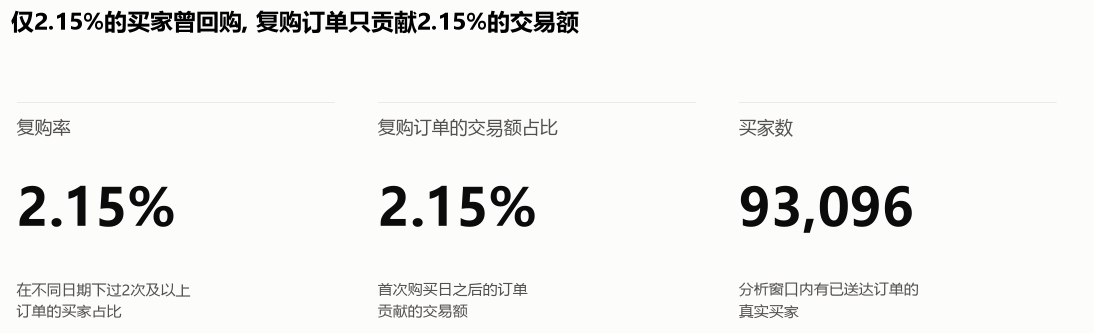

In [5]:
repurchase_rate = df_rep["rate_rebuy_d"].iloc[0]          # 定义B的复购率
repeat_gmv_share = df_rep_gmv["rate_re_gmv"].iloc[0]
n_buyers = df_rep["buyers"].iloc[0]

tiles = [
    (f"{repurchase_rate:.2%}",  "复购率",             "在不同日期下过2次及以上\n订单的买家占比"),
    (f"{repeat_gmv_share:.2%}", "复购订单的交易额占比", "首次购买日之后的订单\n贡献的交易额"),
    (f"{n_buyers:,}",           "买家数",             "分析窗口内有已送达订单的\n真实买家"),
]

fig, axes = plt.subplots(1, len(tiles), figsize=(10, 3))
for ax, (value, label, note) in zip(axes, tiles):
    ax.set_axis_off()
    ax.text(0.0, 0.92, label, fontsize=12, color=COLORS["text_secondary"], va="top")
    ax.text(0.0, 0.62, value, fontsize=34, fontweight="bold", color=COLORS["text"], va="top")
    ax.text(0.0, 0.18, note, fontsize=9.5, color=COLORS["text_secondary"], va="top", linespacing=1.4)
    ax.axhline(1.0, xmin=0, xmax=0.92, color=COLORS["grid"], linewidth=1)

fig.suptitle("仅2.15%的买家曾回购, 复购订单只贡献2.15%的交易额", x=0.01, ha="left", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig("../docs/figures/m5_repurchase.png", dpi=150, bbox_inches="tight")
plt.show()